# 01 - Dataset 1 (EMSCAD): feature engineering and baseline

This notebook turns the frozen train and test files from notebook 00 into model-ready features, checks which feature blocks carry signal, fits a simple logistic-regression baseline, and writes the feature-engineered files that the modelling notebooks start from.

**Sections**
1. **Setup and data**
2. **Feature plan**: the feature blocks, the A0 to A3 ladder, and how missing values and scales are handled.
3. **Row-wise features**: computed from a single posting, nothing learned from the data.
4. **Learned features**: category encodings, TF-IDF and the fraud-phrase score, all fitted on training rows only.
5. **Feature sets and pipelines**: A0 to A3 and the logistic-regression pipeline.
6. **Checks**: leakage, signal and redundancy, the ladder, scaling, group size, and the block ablation.
7. **Baseline**: logistic regression with out-of-fold metrics.
8. **Outputs**: the feature-engineered train and test files, the feature dictionary and the tables.

**The rule that keeps the test set honest.** A feature is either *row-wise* (computed from one posting alone, such as "company profile is empty") or *learned* (needs the data or the labels, such as a TF-IDF vocabulary or a list of fraud-leaning phrases). Row-wise features can be computed on any rows. Learned features are fitted on training rows only, and inside cross-validation on the training part of each fold only, then applied to the other rows. The test file is read in this notebook but is not used to fit or score anything unless the single switch in section 7 is turned on.

**Requirements.** Run notebook 00 first so that `data/processed/d1_train.csv` and `data/processed/d1_test.csv` exist. Needs `scikit-learn`, `pandas`, `numpy`, `matplotlib` and `seaborn`. The ablation in section 6 takes roughly 15 to 25 minutes; its repeat count is set by `ABLATION_REPEATS`.

In [1]:
import html
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)

# Find the project folder by looking upward for the processed train file.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "processed" / "d1_train.csv").exists()), Path.cwd())
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
TAB_DIR = ROOT / "reports" / "tables"
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
ABLATION_REPEATS = 5          # repeats of 5-fold CV in the ablation (use 2 for a quick run)
TARGET = "fraudulent"
GROUP = "group_id"
TEXT_COLS = ["title", "company_profile", "description", "requirements", "benefits"]
RAW_BINARY = ["telecommuting", "has_company_logo", "has_questions"]
RAW_CAT = ["employment_type", "required_experience", "required_education", "industry", "function"]

train = pd.read_csv(PROCESSED_DIR / "d1_train.csv")
test = pd.read_csv(PROCESSED_DIR / "d1_test.csv")
for d in (train, test):
    if "country" not in d.columns:
        d["country"] = d["location"].fillna("").str.split(",").str[0].str.strip().str.upper().replace("", "UNK")

assert set(train[GROUP]).isdisjoint(set(test[GROUP])), "train and test share groups"
y_train = train[TARGET].to_numpy()
groups_train = train[GROUP].to_numpy()

print("Project folder:", ROOT)
print(f"train: {train.shape} | fraud {y_train.mean():.2%} | groups {train[GROUP].nunique():,}")
print(f"test : {test.shape} | fraud {test[TARGET].mean():.2%} | groups {test[GROUP].nunique():,}")

Project folder: /Users/sunxinyang/Documents/bt4012-fake-job-fraud
train: (14439, 21) | fraud 4.80% | groups 3,555
test : (3441, 21) | fraud 5.03% | groups 885


## 2. Feature plan

Features are grouped into five **blocks**. The A0 to A3 ladder adds blocks cumulatively, so the gain from each step can be measured.

| Block | Contents | Learned from data? |
|---|---|---|
| `raw` | The three binary fields and the five category fields as given, with a "MISSING" category | Category list only (fitted on train) |
| `engineered` | Missing-field flags and count, masked email, phone and URL flags, salary parsing, country | Country list only (fitted on train) |
| `text_style` | Lengths, capital letters, digits, exclamation marks, money symbols and similar style statistics | No |
| `tfidf` | TF-IDF weights of words and two-word phrases in the combined text | Vocabulary and weights (text only, no labels) |
| `lexicon` | How many fraud-leaning and legitimate-leaning phrases a posting contains, and their combined weight | Yes: the phrase list uses the labels |

| Set | Blocks | Question it answers |
|---|---|---|
| **A0** | `raw` | How far do the fields as given get us? |
| **A1** | `raw` + `engineered` | What does domain-motivated feature work add? |
| **A2** | A1 + `text_style` + `tfidf` | What does the posting text add? |
| **A3** | A2 + `lexicon` | Does an explicit fraud-phrase score add anything beyond TF-IDF? |

The blocks are listed in one dictionary, `FEATURE_SETS`, in section 5. If the ladder used in the report is defined differently, only that dictionary needs to change.

**Groups are not used as features.** Groups exist only to keep copies of one posting on the same side of every split. Group summaries are left out because the row-level features already carry the variation inside a group. Group size is the one exception worth testing: it reflects how EMSCAD was sampled and could not be computed for a single new posting, so it is checked in section 6 as an observation and a one-off experiment, outside the ladder.

### Missing values
Missingness is informative here (a missing company profile is far more common in fraudulent postings), so values are not imputed away.

| Where | Handling | Why |
|---|---|---|
| Optional fields | One missing flag per field, plus `n_missing_fields`, the number of optional fields left empty | The flag keeps the signal; the count summarises how sparse a posting is |
| Category fields | One-hot with an explicit `MISSING` level | The `MISSING` level repeats the matching flag; harmless, left in |
| Salary | Numeric values are 0 when absent, next to the salary flags | The flags carry the signal; the 0 only keeps the column numeric |
| Text | Empty text gives zero length and an all-zero TF-IDF row | Empty text is itself informative |
| Tree models | Can read missing values directly, so the modelling notebooks may pass them as NaN | Trees learn which side missing values belong to |

### Scaling
| Features | Treatment |
|---|---|
| Numeric engineered, text style, phrase score | Standardised, with the mean and spread taken from the training rows of each fold |
| Binary flags | Left as 0/1 |
| TF-IDF | Each row is length-normalised (the default) |
| Dense blocks next to TF-IDF | A single `dense_weight` shrinks the standardised dense blocks, so that under an L2 penalty they do not outweigh the small TF-IDF weights. Checked in section 6 |

## 3. Row-wise features

These features use one posting at a time and learn nothing, so the same function is applied to train and test and cannot leak. The choices follow the findings of notebook 00: a missing company profile, a missing logo, masked contact details and country were the clearest signals, and a missing field is itself informative, so each optional field gets a missing flag.

Text preparation first. HTML entities such as `&amp;` are decoded, and masked contact details such as `#EMAIL_8e4c...#` become fixed tokens (`emailph`, `phoneph`, `urlph`) so that a unique hash is not treated as a word.

In [2]:
PLACEHOLDER = r"#(URL|EMAIL|PHONE)_[A-Za-z0-9]+#"
MISSING_FLAG_COLS = ["company_profile", "location", "department", "requirements", "benefits", "employment_type",
                     "required_experience", "required_education", "industry", "function"]


def prepare_text(df):
    """Return the combined text, with HTML decoded and masked contact details replaced by tokens."""
    text_all = df[TEXT_COLS].fillna("").astype(str).agg(" ".join, axis=1)
    text_clean = (text_all.map(html.unescape)
                  .str.replace(PLACEHOLDER, lambda m: f" {m.group(1).lower()}ph ", regex=True))
    return text_all, text_clean


def build_rowwise(df):
    """Compute every row-wise feature. Returns (features, spec), where spec maps
    feature name -> (block, kind) and kind is 'binary' or 'numeric'."""
    text_all, text_clean = prepare_text(df)
    n_chars = text_clean.str.len().clip(lower=1)
    n_words = text_clean.str.split().str.len().clip(lower=1)
    feats, spec = {}, {}

    def add(name, values, block, kind):
        feats[name] = values.astype("int8") if kind == "binary" else values.astype(float)
        spec[name] = (block, kind)

    # --- engineered: missing fields and masked contact details
    for col in MISSING_FLAG_COLS:
        add(f"missing_{col}", df[col].isna(), "engineered", "binary")
    optional = ["salary_range"] + MISSING_FLAG_COLS
    add("n_missing_fields", df[optional].isna().sum(axis=1), "engineered", "numeric")
    for kind in ("url", "email", "phone"):
        add(f"has_{kind}_placeholder", text_all.str.contains(f"#{kind.upper()}_", regex=False), "engineered", "binary")
    add("country_us", df["country"].eq("US"), "engineered", "binary")
    add("has_exclamation", text_all.str.contains("!", regex=False), "engineered", "binary")
    add("title_all_caps", df["title"].fillna("").str.isupper(), "engineered", "binary")

    # --- engineered: salary. The field is free text; some entries are spreadsheet date
    # conversions such as '10-Oct', and the currency and period are not recorded.
    sal = df["salary_range"].fillna("").astype(str).str.strip()
    numeric_range = sal.str.fullmatch(r"\d+\s*-\s*\d+")
    bounds = sal.where(numeric_range).str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
    lo, hi = bounds[0], bounds[1]
    add("has_salary", sal.ne(""), "engineered", "binary")
    add("salary_is_numeric_range", numeric_range, "engineered", "binary")
    add("salary_looks_like_date", sal.str.fullmatch(r"\d{1,2}-[A-Za-z]{3}|[A-Za-z]{3}-\d{1,2}"), "engineered", "binary")
    add("salary_min_log", np.log1p(lo).fillna(0), "engineered", "numeric")
    add("salary_max_log", np.log1p(hi).fillna(0), "engineered", "numeric")
    add("salary_span_log", np.log1p((hi - lo).clip(lower=0)).fillna(0), "engineered", "numeric")

    # --- text style
    for col in TEXT_COLS:
        add(f"words_{col}_log", np.log1p(df[col].fillna("").astype(str).str.split().str.len()), "text_style", "numeric")
    add("words_total_log", np.log1p(n_words), "text_style", "numeric")
    add("caps_ratio", text_clean.str.count(r"[A-Z]") / text_clean.str.count(r"[A-Za-z]").clip(lower=1), "text_style", "numeric")
    add("digit_ratio", text_clean.str.count(r"\d") / n_chars, "text_style", "numeric")
    add("exclaim_per_1k_chars", text_clean.str.count("!") / n_chars * 1000, "text_style", "numeric")
    add("money_symbols_log", np.log1p(text_clean.str.count(r"[$£€]")), "text_style", "numeric")
    add("long_caps_words_log", np.log1p(text_clean.str.count(r"\b[A-Z]{4,}\b")), "text_style", "numeric")
    add("avg_word_length", n_chars / n_words, "text_style", "numeric")
    add("unique_word_share", text_clean.str.lower().str.split().map(lambda w: len(set(w)) / max(len(w), 1)), "text_style", "numeric")
    add("html_entities_log", np.log1p(text_all.str.count(r"&(?:[A-Za-z]+|#\d+);")), "text_style", "numeric")
    add("url_placeholders_log", np.log1p(text_all.str.count("#URL_")), "text_style", "numeric")
    add("title_caps_share", df["title"].fillna("").map(lambda s: sum(c.isupper() for c in s) / max(sum(c.isalpha() for c in s), 1)), "text_style", "numeric")

    return pd.DataFrame(feats, index=df.index), spec


t0 = time.time()
rw_train, ROWWISE_SPEC = build_rowwise(train)
rw_test, spec_test = build_rowwise(test)
assert ROWWISE_SPEC == spec_test and list(rw_train.columns) == list(rw_test.columns)
print(f"{rw_train.shape[1]} row-wise features built for train and test in {time.time() - t0:.0f}s")
print("no missing values:", not rw_train.isna().any().any() and not rw_test.isna().any().any())

ROWWISE_BINARY = [c for c, (b, k) in ROWWISE_SPEC.items() if k == "binary"]
ROWWISE_NUMERIC_ENG = [c for c, (b, k) in ROWWISE_SPEC.items() if b == "engineered" and k == "numeric"]
ROWWISE_STYLE = [c for c, (b, k) in ROWWISE_SPEC.items() if b == "text_style"]

39 row-wise features built for train and test in 7s
no missing values: True


## 4. Learned features

These features need the data, so each one is an estimator that is fitted on training rows and then applied to other rows. They are used inside scikit-learn pipelines so that, during cross-validation, they are refitted on the training part of every fold.

### Inputs table
One table holds everything the pipelines read: the row-wise features, the raw fields, the country, the cleaned text and the group id.

In [3]:
def build_inputs(df, rowwise):
    _, text_clean = prepare_text(df)
    out = pd.concat([rowwise, df[RAW_BINARY + RAW_CAT + ["country", GROUP]]], axis=1)
    out["text_clean"] = text_clean
    return out


X_train = build_inputs(train, rw_train)
X_test = build_inputs(test, rw_test)
print("input columns:", X_train.shape[1], "| train rows:", len(X_train), "| test rows:", len(X_test))

input columns: 50 | train rows: 14439 | test rows: 3441


### Fraud-phrase score (the `lexicon` block)

Notebook 00 found words and two-word phrases that are over-represented in fraudulent postings. This transformer turns that idea into three features per posting: how many fraud-leaning phrases it contains, how many legitimate-leaning phrases, and the summed log-odds weight of all the phrases it contains.

How it is built, and why:
- **Phrase ranking** uses weighted log-odds with an informative Dirichlet prior (Monroe, Colaresi and Quinn, 2008), which keeps rare phrases from dominating.
- **One posting per group** is used when ranking, so a template reposted hundreds of times counts once.
- **Out-of-fold scores for the training rows.** If a phrase list were built from the training rows and then used to score those same rows, the labels would leak into the feature and the model would trust it too much. Training rows are therefore scored with a list built from the other inner folds. Rows from other data (validation or test) are scored with the list built from all training rows.
- The phrase vocabulary is counted without labels; only the ranking uses them.

In [4]:
def one_per_group(groups, seed):
    """Positions of one random row per group."""
    perm = np.random.default_rng(seed).permutation(len(groups))
    _, first = np.unique(groups[perm], return_index=True)
    return perm[first]


def weighted_log_odds(counts, y, alpha0=500.0, min_docs=5):
    """Weighted log-odds (fraud vs legitimate) and z-scores for a documents-by-phrases count matrix.
    Phrases seen in fewer than `min_docs` of these documents get z = 0 and are never selected."""
    fraud, legit = counts[np.flatnonzero(y == 1)], counts[np.flatnonzero(y == 0)]
    yf = np.asarray(fraud.sum(axis=0)).ravel().astype(float)
    yl = np.asarray(legit.sum(axis=0)).ravel().astype(float)
    docs = np.asarray((counts > 0).sum(axis=0)).ravel()
    prior = yf + yl
    valid = (prior > 0) & (docs >= min_docs)
    alpha = alpha0 * prior / max(prior.sum(), 1.0)
    nf, nl = yf.sum(), yl.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        delta = (np.log((yf + alpha) / (nf + alpha0 - yf - alpha))
                 - np.log((yl + alpha) / (nl + alpha0 - yl - alpha)))
        z = delta / np.sqrt(1.0 / (yf + alpha) + 1.0 / (yl + alpha))
    delta, z = np.where(valid, delta, 0.0), np.where(valid, z, 0.0)
    return delta, z, valid


class FraudPhraseScore(BaseEstimator, TransformerMixin):
    # Input: a DataFrame with columns `text_clean` and `group_id`. Output: 3 columns.
    def __init__(self, n_fraud=50, n_legit=20, min_df=5, ngram_range=(1, 2), inner_splits=3, seed=42):
        self.n_fraud, self.n_legit, self.min_df = n_fraud, n_legit, min_df
        self.ngram_range, self.inner_splits, self.seed = ngram_range, inner_splits, seed

    def _lexicon(self, counts, y, groups):
        pick = one_per_group(groups, self.seed)
        delta, z, valid = weighted_log_odds(counts[pick], y[pick])
        fraud = np.argsort(-np.where(valid, z, -np.inf))[:self.n_fraud]
        legit = np.argsort(np.where(valid, z, np.inf))[:self.n_legit]
        fraud, legit = fraud[z[fraud] > 0], legit[z[legit] < 0]
        return fraud, legit, delta

    @staticmethod
    def _score(present, fraud, legit, delta):
        n_fraud = np.asarray(present[:, fraud].sum(axis=1)).ravel()
        n_legit = np.asarray(present[:, legit].sum(axis=1)).ravel()
        chosen = np.r_[fraud, legit].astype(int)
        weight = np.asarray(present[:, chosen] @ delta[chosen]).ravel()
        return np.c_[np.log1p(n_fraud), np.log1p(n_legit), weight]

    def fit_transform(self, X, y):
        texts, groups, y = X["text_clean"].to_numpy(), X[GROUP].to_numpy(), np.asarray(y)
        self.vec_ = CountVectorizer(ngram_range=self.ngram_range, min_df=self.min_df, lowercase=True, dtype=np.int32)
        counts = self.vec_.fit_transform(texts).tocsr()      # vocabulary only, no labels
        present = (counts > 0).astype(np.float32).tocsr()
        self.fraud_, self.legit_, self.delta_ = self._lexicon(counts, y, groups)
        out = np.zeros((len(y), 3))
        inner = StratifiedGroupKFold(n_splits=self.inner_splits, shuffle=True, random_state=self.seed)
        for fit_idx, score_idx in inner.split(texts, y, groups):
            fraud, legit, delta = self._lexicon(counts[fit_idx], y[fit_idx], groups[fit_idx])
            out[score_idx] = self._score(present[score_idx], fraud, legit, delta)
        return out

    def fit(self, X, y):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        present = (self.vec_.transform(X["text_clean"].to_numpy()) > 0).astype(np.float32).tocsr()
        return self._score(present, self.fraud_, self.legit_, self.delta_)

    def get_feature_names_out(self, input_features=None):
        return np.array(["fraud_phrase_count_log", "legit_phrase_count_log", "phrase_weight_sum"])

### Which phrases does the list contain?
The list built from all training rows, to confirm it holds sensible scam-style wording and nothing that identifies a single employer. This fit is for inspection only; the cross-validation below refits it per fold.

In [5]:
lex = FraudPhraseScore().fit(X_train[["text_clean", GROUP]], y_train)
terms = lex.vec_.get_feature_names_out()
print("Fraud-leaning phrases:", ", ".join(terms[lex.fraud_][:30]))
print("\nLegitimate-leaning phrases:", ", ".join(terms[lex.legit_][:20]))

Fraud-leaning phrases: administrative, assistant, data entry, entry, administrative assistant, offshore, oil, engineering, gas, word, manufacturing, receptionist, hotel, clerk, equipment, mechanical, duties, safety, clerical, earn, oil and, church, time, and gas, operations, personnel, part time, bottom line, customer service, excel

Legitimate-leaning phrases: our, we, you, web, marketing, team, re, media, software, social, mobile, developer, we re, growing, that, will, clients, new, you will, creative


## 5. Feature sets and pipelines

Each set is a `ColumnTransformer` built from the blocks it contains. All of its learned parts are fitted when the pipeline is fitted, so putting it in a pipeline with a model and cross-validating is leakage-safe.

Choices that apply to every set:
- **Category fields** become one-hot columns with a "MISSING" category; values seen fewer than 50 times (100 for country) are pooled into one "other" column, and values unseen at fit time are pooled the same way, so test postings with a new country do not break the pipeline.
- **Numeric engineered and text-style features, and the phrase score,** are standardised; binary features are passed through unchanged.
- **TF-IDF** uses words and two-word phrases (`min_df=5`, `max_df=0.5`, at most 30,000 terms, sublinear term frequency, English stop words removed).
- **`dense_weight`** multiplies the standardised dense blocks. At 1.0 they are used as they are.

`repeated_grouped_cv` scores a feature set with a class-weighted logistic regression in repeated 5-fold cross-validation that keeps whole groups together. Every learned feature is refitted inside each fold.

In [6]:
FEATURE_SETS = {
    "A0": ["raw"],
    "A1": ["raw", "engineered"],
    "A2": ["raw", "engineered", "text_style", "tfidf"],
    "A3": ["raw", "engineered", "text_style", "tfidf", "lexicon"],
}
DENSE_PARTS = {"salary_numeric", "text_style", "lexicon", "extra_numeric"}


def one_hot(min_frequency):
    return Pipeline([
        ("fill", SimpleImputer(strategy="constant", fill_value="MISSING")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency)),
    ])


def make_features(level=None, blocks=None, extra_numeric=(), dense_weight=1.0):
    """Feature pipeline for a ladder level (e.g. 'A3') or for an explicit list of blocks."""
    blocks = blocks if blocks is not None else FEATURE_SETS[level]
    parts = []
    if "raw" in blocks:
        parts += [("raw_binary", "passthrough", RAW_BINARY), ("raw_category", one_hot(50), RAW_CAT)]
    if "engineered" in blocks:
        parts += [("flags", "passthrough", ROWWISE_BINARY),
                  ("salary_numeric", StandardScaler(), ROWWISE_NUMERIC_ENG),
                  ("country", one_hot(100), ["country"])]
    if "text_style" in blocks:
        parts += [("text_style", StandardScaler(), ROWWISE_STYLE)]
    if "tfidf" in blocks:
        parts += [("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, max_features=30000,
                                            sublinear_tf=True, stop_words="english", dtype=np.float32), "text_clean")]
    if "lexicon" in blocks:
        parts += [("lexicon", Pipeline([("score", FraudPhraseScore()), ("scale", StandardScaler())]),
                   ["text_clean", GROUP])]
    if extra_numeric:
        parts += [("extra_numeric", StandardScaler(), list(extra_numeric))]
    weights = {name: dense_weight for name, *_ in parts if name in DENSE_PARTS}
    return ColumnTransformer(parts, sparse_threshold=1.0, remainder="drop", transformer_weights=weights or None)


def logistic_pipeline(blocks, extra_numeric=(), dense_weight=1.0, C=0.3):
    return Pipeline([
        ("features", make_features(blocks=blocks, extra_numeric=extra_numeric, dense_weight=dense_weight)),
        ("model", LogisticRegression(solver="liblinear", class_weight="balanced", C=C, max_iter=2000)),
    ])


def repeated_grouped_cv(blocks, n_repeats=1, n_splits=5, seed=SEED, extra_numeric=(), dense_weight=1.0):
    """PR-AUC for every fold of `n_repeats` group-aware, stratified n_splits-fold cross-validations."""
    scores = []
    for r in range(n_repeats):
        folds = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        for fit_idx, val_idx in folds.split(X_train, y_train, groups_train):
            assert set(groups_train[fit_idx]).isdisjoint(groups_train[val_idx])
            pipe = logistic_pipeline(blocks, extra_numeric, dense_weight)
            pipe.fit(X_train.iloc[fit_idx], y_train[fit_idx])
            proba = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
            scores.append(average_precision_score(y_train[val_idx], proba))
    return np.array(scores)


rows = []
for level in FEATURE_SETS:
    t0 = time.time()
    ct = make_features(level).fit(X_train, y_train)
    names = ct.get_feature_names_out()
    by_part = pd.Series([n.split("__")[0] for n in names]).value_counts()
    rows.append({"set": level, "blocks": " + ".join(FEATURE_SETS[level]), "n_features": len(names),
                 "fit_seconds": round(time.time() - t0, 1), **by_part.to_dict()})
summary = pd.DataFrame(rows).set_index("set").fillna(0)
display(summary)

,blocks,n_features,fit_seconds,raw_category,raw_binary,flags,country,salary_numeric,tfidf,text_style,lexicon
set,,,,,,,,,,,
A0,raw,94,0.1,91,3,0.0,0.0,0.0,0.0,0.0,0.0
A1,raw + engineered,130,0.1,91,3,19.0,13.0,4.0,0.0,0.0,0.0
A2,raw + engineered + text_style + tfidf,30146,7.4,91,3,19.0,13.0,4.0,30000.0,16.0,0.0
A3,raw + engineered + text_style + tfidf + lexicon,30149,14.2,91,3,19.0,13.0,4.0,30000.0,16.0,3.0


## 6. Checks

### Leakage checks
The pipelines must not read the target or the row id as features, and the test rows must come through a pipeline fitted on training rows only. The check looks at the input columns the pipeline reads, not at the output names: a TF-IDF column can be named after a word such as "fraudulent" that appears in posting text, which is not the target column.

In [7]:
final_a3 = make_features("A3").fit(X_train, y_train)      # fitted on training rows only
names = final_a3.get_feature_names_out()

used_columns = {c for _, transformer, cols in final_a3.transformers_ if not isinstance(transformer, str)
                for c in ([cols] if isinstance(cols, str) else cols)}
leaked = used_columns & {TARGET, "job_id"}
assert not leaked, leaked
print("columns read by the pipeline:", len(used_columns))

test_matrix = final_a3.transform(X_test)                  # transform only: the test file is not used to fit
print("A3 feature count:", len(names))
print("test matrix:", test_matrix.shape, "| columns match train:", test_matrix.shape[1] == len(names))
print("any NaN in test matrix:", bool(np.isnan(test_matrix.toarray()).any()))

columns read by the pipeline: 50
A3 feature count: 30149
test matrix: (3441, 30149) | columns match train: True
any NaN in test matrix: False


### Signal and redundancy of the row-wise features
For every row-wise feature on training rows: how common it is and how well it alone separates fraud from legitimate postings (ROC AUC, 0.5 = no signal; below 0.5 means a higher value goes with fewer frauds). One posting per group is used, so copies of one template do not inflate the result, which also means the shares differ from the row-level shares in the data overview. Features that are almost copies of each other are listed so redundant ones can be spotted.

In [8]:
pick = one_per_group(groups_train, SEED)
rw_pick, y_pick = rw_train.iloc[pick], y_train[pick]

signal = pd.DataFrame({
    "block": [ROWWISE_SPEC[c][0] for c in rw_pick.columns],
    "kind": [ROWWISE_SPEC[c][1] for c in rw_pick.columns],
    "mean_or_share": rw_pick.mean().round(3).to_numpy(),
    "auc": [roc_auc_score(y_pick, rw_pick[c]) if rw_pick[c].nunique() > 1 else np.nan for c in rw_pick.columns],
}, index=rw_pick.columns)
signal["distance_from_0.5"] = (signal["auc"] - 0.5).abs()
signal = signal.sort_values("distance_from_0.5", ascending=False).drop(columns="distance_from_0.5")
display(signal.round(3))
signal.to_csv(TAB_DIR / "rowwise_feature_signal.csv")

corr = rw_pick.loc[:, rw_pick.nunique() > 1].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
high = pairs[pairs["spearman"].abs() >= 0.8].sort_values("spearman", key=abs, ascending=False)
print(f"\nPairs with |Spearman| >= 0.8: {len(high)}")
display(high.round(3))

,block,kind,mean_or_share,auc
words_company_profile_log,text_style,numeric,1.726,0.349
missing_company_profile,engineered,binary,0.610,0.649
words_total_log,text_style,numeric,5.514,0.354
unique_word_share,text_style,numeric,0.651,0.627
words_requirements_log,text_style,numeric,3.473,0.379
country_us,engineered,binary,0.552,0.617
caps_ratio,text_style,numeric,0.052,0.588
n_missing_fields,engineered,numeric,4.468,0.583
missing_required_experience,engineered,binary,0.398,0.574
avg_word_length,text_style,numeric,7.253,0.568



Pairs with |Spearman| >= 0.8: 15


,feature_a,feature_b,spearman
681,has_salary,salary_is_numeric_range,0.993
466,has_url_placeholder,url_placeholders_log,0.989
616,has_exclamation,exclaim_per_1k_chars,0.985
801,salary_min_log,salary_max_log,0.979
841,salary_max_log,salary_span_log,0.972
24,missing_company_profile,words_company_profile_log,-0.961
723,salary_is_numeric_range,salary_max_log,0.946
802,salary_min_log,salary_span_log,0.942
684,has_salary,salary_max_log,0.939
722,salary_is_numeric_range,salary_min_log,0.927


### The A0 to A3 ladder
Each set feeds the same logistic regression in 5-fold grouped cross-validation. Scores are PR-AUC for the fraud class; a model with no skill scores about the fraud rate. This shows that the blocks carry signal and the pipelines run cleanly. Folds vary a lot because only a few hundred independent fraud groups exist, so differences of a few hundredths are not meaningful on their own; the paired comparison further down puts intervals on them.

,mean_pr_auc,sd_across_folds,fold_1,fold_2,fold_3,fold_4,fold_5,seconds
set,,,,,,,,
A0,0.285,0.162,0.202,0.252,0.557,0.282,0.131,1
A1,0.387,0.089,0.503,0.370,0.431,0.368,0.263,1
A2,0.545,0.121,0.727,0.503,0.527,0.575,0.394,39
A3,0.560,0.129,0.671,0.525,0.598,0.654,0.353,75


No-skill PR-AUC is about the fraud rate: 0.048


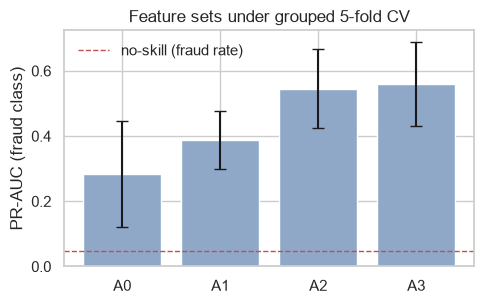

In [9]:
cv_rows = []
for level in FEATURE_SETS:
    t0 = time.time()
    scores = repeated_grouped_cv(FEATURE_SETS[level])
    cv_rows.append({"set": level, "mean_pr_auc": scores.mean(), "sd_across_folds": scores.std(ddof=1),
                    **{f"fold_{i + 1}": s for i, s in enumerate(scores)}, "seconds": round(time.time() - t0)})
cv = pd.DataFrame(cv_rows).set_index("set")
display(cv.round(3))
print(f"No-skill PR-AUC is about the fraud rate: {y_train.mean():.3f}")
cv.to_csv(TAB_DIR / "feature_sets_sanity_cv.csv")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(cv.index, cv["mean_pr_auc"], yerr=cv["sd_across_folds"], color="#8fa8c8", capsize=4)
ax.axhline(y_train.mean(), color="#c0504d", linestyle="--", linewidth=1, label="no-skill (fraud rate)")
ax.set_ylabel("PR-AUC (fraud class)")
ax.set_title("Feature sets under grouped 5-fold CV")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fe_feature_sets_sanity_cv.png", dpi=200)
plt.show()

### Scaling check
Standardised dense features sit around plus or minus 1, while TF-IDF weights are tiny, so under an L2 penalty the dense blocks can outweigh the text. `dense_weight` shrinks them. This compares A2 and A3 with the dense blocks at full weight and at 0.3, on the same folds.

In [10]:
rows = []
for level in ("A2", "A3"):
    for weight in (1.0, 0.3):
        s = repeated_grouped_cv(FEATURE_SETS[level], dense_weight=weight)
        rows.append({"set": level, "dense_weight": weight, "mean_pr_auc": s.mean(), "sd_across_folds": s.std(ddof=1)})
scaling_check = pd.DataFrame(rows)
display(scaling_check.round(3))
scaling_check.to_csv(TAB_DIR / "dense_weight_check.csv", index=False)

,set,dense_weight,mean_pr_auc,sd_across_folds
0,A2,1.0,0.545,0.121
1,A2,0.3,0.552,0.124
2,A3,1.0,0.560,0.129
3,A3,0.3,0.563,0.129


### Group size and fraud (observation only)
Group size is not a feature in the ladder. This table shows whether larger groups are more or less often fraudulent, by posting and by group, and a one-off check shows whether adding group size to A3 changes the score. Group size depends on how the dataset was sampled, so a gain here would not carry over to a single new posting.

In [11]:
group_size = train.groupby(GROUP)[GROUP].transform("size")
size_bins = [0, 1, 2, 5, 20, np.inf]
size_labels = ["1", "2", "3-5", "6-20", "21+"]

by_posting = (train.groupby(pd.cut(group_size, size_bins, labels=size_labels), observed=True)[TARGET]
              .agg(postings="size", fraud_rate_of_postings="mean"))
per_group = train.groupby(GROUP).agg(size=(GROUP, "size"), fraud=(TARGET, "max"))
by_group = (per_group.groupby(pd.cut(per_group["size"], size_bins, labels=size_labels), observed=True)["fraud"]
            .agg(groups="size", fraud_rate_of_groups="mean"))
group_size_table = by_posting.join(by_group)
group_size_table.index.name = "group_size"
display(group_size_table.round(3))
group_size_table.to_csv(TAB_DIR / "group_size_vs_fraud.csv")

# One-off experiment: A3 with group size added (same folds as the ladder check)
X_train["group_size_log"] = np.log1p(group_size).to_numpy()
with_size = repeated_grouped_cv(FEATURE_SETS["A3"], extra_numeric=["group_size_log"])
print(f"A3: {cv.loc['A3', 'mean_pr_auc']:.3f} | A3 + group size: {with_size.mean():.3f} "
      f"(sd across folds {with_size.std(ddof=1):.3f})")
X_train = X_train.drop(columns="group_size_log")

,postings,fraud_rate_of_postings,groups,fraud_rate_of_groups
group_size,,,,
1,2434,0.108,2434,0.108
2,636,0.093,318,0.094
3-5,1320,0.042,351,0.046
6-20,3618,0.044,343,0.047
21+,6431,0.024,109,0.055


A3: 0.560 | A3 + group size: 0.549 (sd across folds 0.119)


### Block ablation
Blocks, not single columns, are the unit: of the thousands of features, almost all are TF-IDF columns. Each block is removed from A3 in turn, a few compact sets are scored, and every configuration is compared with the same reference on the same folds (repeated 5-fold grouped cross-validation).

For each configuration the table reports the drop in mean PR-AUC against the full set and the share of folds in which it scored lower. A block that matters should hurt in most folds. The paired table then gives the mean difference from a reference with an interval that allows for the overlap between training sets (the Nadeau and Bengio correction). With few independent fraud groups the intervals are wide, so only large differences can be established.

In [13]:
FULL = FEATURE_SETS["A2"]
configs = {"A2 (all blocks)": FULL}
configs.update({f"A2 without {b}": [x for x in FULL if x != b] for b in FULL})
configs.update({
    "tfidf only": ["tfidf"],
    "engineered + tfidf": ["engineered", "tfidf"],
    "raw + engineered + tfidf": ["raw", "engineered", "tfidf"],
})

t0 = time.time()
results = {name: repeated_grouped_cv(blocks, n_repeats=ABLATION_REPEATS) for name, blocks in configs.items()}
print(f"ablation finished in {(time.time() - t0) / 60:.1f} minutes")

base = results["A2 (all blocks)"]
ablation = pd.DataFrame({
    name: {"mean_pr_auc": s.mean(), "drop_vs_full": base.mean() - s.mean(),
           "share_of_folds_hurt": (s < base).mean()}
    for name, s in results.items()}).T
display(ablation.round(3))
ablation.to_csv(TAB_DIR / "ablation_blocks.csv")


def paired_vs(ref_name, all_results, n_splits=5):
    """Mean fold-by-fold difference from a reference, with an approximate 95% interval."""
    ref = all_results[ref_name]
    rows = {}
    for name, s in all_results.items():
        if name == ref_name:
            continue
        d = s - ref
        se = np.sqrt((1 / len(d) + 1 / (n_splits - 1)) * d.var(ddof=1))      # Nadeau-Bengio corrected
        rows[name] = {"mean_diff": d.mean(), "se": se, "low": d.mean() - 2 * se, "high": d.mean() + 2 * se,
                      "share_folds_better": (d > 0).mean()}
    return pd.DataFrame(rows).T


print("\nDifference from the TF-IDF-only reference (negative = lower than TF-IDF alone):")
paired = paired_vs("tfidf only", results)
display(paired.round(3))
paired.to_csv(TAB_DIR / "ablation_paired_vs_tfidf_only.csv")

ablation finished in 21.2 minutes


,mean_pr_auc,drop_vs_full,share_of_folds_hurt
A2 (all blocks),0.549,0.000,0.00
A2 without raw,0.525,0.024,0.64
A2 without engineered,0.510,0.039,0.76
A2 without text_style,0.556,-0.007,0.52
A2 without tfidf,0.399,0.149,1.00
tfidf only,0.578,-0.029,0.44
engineered + tfidf,0.528,0.020,0.64
raw + engineered + tfidf,0.556,-0.007,0.52



Difference from the TF-IDF-only reference (negative = lower than TF-IDF alone):


,mean_diff,se,low,high,share_folds_better
A2 (all blocks),-0.029,0.043,-0.116,0.058,0.44
A2 without raw,-0.053,0.063,-0.179,0.073,0.32
A2 without engineered,-0.068,0.058,-0.183,0.048,0.28
A2 without text_style,-0.022,0.047,-0.116,0.072,0.40
A2 without tfidf,-0.178,0.043,-0.265,-0.092,0.04
engineered + tfidf,-0.049,0.065,-0.179,0.080,0.40
raw + engineered + tfidf,-0.022,0.047,-0.116,0.072,0.40


## 7. Baseline: logistic regression

The baseline is a class-weighted logistic regression on TF-IDF alone, the simplest text model. The full A3 set is scored next to it for comparison. Both are scored on **out-of-fold predictions**: every training posting is predicted by a model that never saw its group, so the numbers are an honest estimate and the test set stays untouched.

Reported for the fraud class, not accuracy:
- **PR-AUC** and **ROC AUC** over all out-of-fold predictions.
- **Precision, recall and F1** at the threshold that maximises F1 on these predictions. That threshold is picked on the same predictions, so it is optimistic; the modelling notebooks should choose thresholds inside nested folds.
- **Review budget**: precision and recall if only the top 5% of postings by score are sent for human review.

,pr_auc,roc_auc,threshold,precision,recall,f1,share_flagged,precision_top5pct,recall_top5pct
TF-IDF only,0.541,0.910,0.646,0.705,0.420,0.526,0.029,0.480,0.499
A3 (all blocks),0.498,0.928,0.772,0.503,0.586,0.541,0.056,0.528,0.550


No-skill PR-AUC is about the fraud rate: 0.048


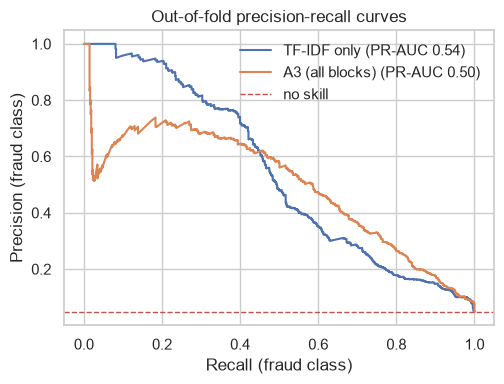

In [14]:
def out_of_fold_scores(blocks, n_splits=5, seed=SEED, dense_weight=1.0):
    oof = np.zeros(len(y_train))
    folds = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fit_idx, val_idx in folds.split(X_train, y_train, groups_train):
        pipe = logistic_pipeline(blocks, dense_weight=dense_weight).fit(X_train.iloc[fit_idx], y_train[fit_idx])
        oof[val_idx] = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
    return oof


def score_summary(y, p, review_share=0.05):
    precision, recall, thresholds = precision_recall_curve(y, p)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    threshold = thresholds[np.argmax(f1)]
    flagged = p >= threshold
    top = np.argsort(-p)[:int(review_share * len(p))]
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p), "threshold": threshold,
            "precision": precision_score(y, flagged), "recall": recall_score(y, flagged), "f1": f1_score(y, flagged),
            "share_flagged": flagged.mean(),
            "precision_top5pct": y[top].mean(), "recall_top5pct": y[top].sum() / y.sum()}


baselines = {"TF-IDF only": ["tfidf"], "A3 (all blocks)": FEATURE_SETS["A3"]}
oof = {name: out_of_fold_scores(blocks) for name, blocks in baselines.items()}
baseline_table = pd.DataFrame({name: score_summary(y_train, p) for name, p in oof.items()}).T
display(baseline_table.round(3))
print(f"No-skill PR-AUC is about the fraud rate: {y_train.mean():.3f}")
baseline_table.to_csv(TAB_DIR / "baseline_logreg_oof_metrics.csv")

fig, ax = plt.subplots(figsize=(5.2, 4))
for name, p in oof.items():
    precision, recall, _ = precision_recall_curve(y_train, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_train, p):.2f})")
ax.axhline(y_train.mean(), color="#c0504d", linestyle="--", linewidth=1, label="no skill")
ax.set_xlabel("Recall (fraud class)")
ax.set_ylabel("Precision (fraud class)")
ax.set_title("Out-of-fold precision-recall curves")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fe_baseline_logreg_pr_curve.png", dpi=200)
plt.show()

### Test-set evaluation (switched off)
The test file is for one final evaluation, after the model, features and threshold are fixed. The switch below stays `False` while features and models are still being changed. Turn it on once, at the very end, and do not change anything afterwards.

In [15]:
EVALUATE_ON_TEST = False      # turn on once, at the very end

if EVALUATE_ON_TEST:
    y_test = test[TARGET].to_numpy()
    final_baseline = logistic_pipeline(["tfidf"]).fit(X_train, y_train)
    p_test = final_baseline.predict_proba(X_test)[:, 1]
    flagged = p_test >= baseline_table.loc["TF-IDF only", "threshold"]       # threshold fixed on the training predictions
    print(f"test PR-AUC {average_precision_score(y_test, p_test):.3f} | ROC AUC {roc_auc_score(y_test, p_test):.3f}")
    print(f"precision {precision_score(y_test, flagged):.3f} | recall {recall_score(y_test, flagged):.3f} | "
          f"F1 {f1_score(y_test, flagged):.3f} | share flagged {flagged.mean():.3f}")
else:
    print("Test evaluation is switched off.")

Test evaluation is switched off.


## 8. Outputs

The feature-engineered files hold the original columns, the country, the group ids and every row-wise feature, for train and test. Only row-wise features are saved: they need no fitting. The learned features (category encodings, TF-IDF and the phrase score) are rebuilt by the pipelines inside each fold, because saving them for the training rows would leak labels into cross-validation.

In [16]:
train_fe = pd.concat([train, rw_train], axis=1)
test_fe = pd.concat([test, rw_test], axis=1)
assert not set(train.columns) & set(rw_train.columns), "name clash between raw and engineered columns"
assert len(train_fe) == len(train) and len(test_fe) == len(test)

train_fe.to_csv(PROCESSED_DIR / "d1_train_feature_engineered.csv", index=False)
test_fe.to_csv(PROCESSED_DIR / "d1_test_feature_engineered.csv", index=False)
print(f"train: {train_fe.shape} | test: {test_fe.shape} | row-wise features: {rw_train.shape[1]}")

block_of = {}
for name in final_a3.get_feature_names_out():
    part = name.split("__")[0]
    block_of[name] = {"raw_binary": "raw", "raw_category": "raw", "flags": "engineered", "salary_numeric": "engineered",
                      "country": "engineered", "text_style": "text_style", "tfidf": "tfidf", "lexicon": "lexicon"}[part]
dictionary = pd.DataFrame({"feature": list(block_of), "block": list(block_of.values())})
dictionary["first_in_set"] = dictionary["block"].map(
    lambda b: next(level for level, blocks in FEATURE_SETS.items() if b in blocks))
dictionary.to_csv(TAB_DIR / "feature_dictionary.csv", index=False)
display(dictionary.groupby(["first_in_set", "block"]).size().rename("n_features").to_frame())

train: (14439, 60) | test: (3441, 60) | row-wise features: 39


n_features
first_in_set block                 
A0           raw                 94
A1           engineered          36
A2           text_style          16
             tfidf            30000
A3           lexicon              3

| Output | Location |
|---|---|
| Train and test files with the row-wise features | `data/processed/d1_train_feature_engineered.csv`, `data/processed/d1_test_feature_engineered.csv` |
| Feature dictionary (one row per A3 feature, with its block and the first set that contains it) | `reports/tables/feature_dictionary.csv` |
| Signal of each row-wise feature | `reports/tables/rowwise_feature_signal.csv` |
| Grouped cross-validation of the ladder | `reports/tables/feature_sets_sanity_cv.csv` |
| Dense-block weight check | `reports/tables/dense_weight_check.csv` |
| Group size against fraud | `reports/tables/group_size_vs_fraud.csv` |
| Block ablation and paired comparison | `reports/tables/ablation_blocks.csv`, `reports/tables/ablation_paired_vs_tfidf_only.csv` |
| Baseline out-of-fold metrics | `reports/tables/baseline_logreg_oof_metrics.csv` |
| Figures | `reports/figures/fe_feature_sets_sanity_cv.png`, `reports/figures/fe_baseline_logreg_pr_curve.png` |

The functions `prepare_text`, `build_rowwise`, `build_inputs`, `FraudPhraseScore`, `FEATURE_SETS`, `make_features` and `logistic_pipeline` are everything the modelling notebooks need, and can be moved to `src/features.py` unchanged.